In [232]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator

In [233]:
def divided_differences(x, y, dy):
  n = len(x)
  Q = np.zeros((2*n, 2*n))
  Z = np.zeros(2*n)
  for i in range(n):
    Z[2*i] = Z[2*i+1] = x[i]
    Q[2*i][0] = Q[2*i+1][0] = y[i]
    Q[2*i+1][1] = dy[i]
    if i>0:
      Q[2*i][1] = (Q[2*i][0] - Q[2*i-1][0]) / (Z[2*i] - Z[2*i-1])
  for j in range(2, 2*n):
    for i in range(j, 2*n):
      Q[i][j] = (Q[i][j-1] - Q[i-1][j-1]) / (Z[i] - Z[i-j])
  return Z, Q

In [234]:
def hermite_interpolation(x, y, dy, xp):
  Z, Q = divided_differences(x, y, dy)
  # Compute polynomial value at xp
  n = len(Z)
  p = Q[0, 0]
  product_term = 1
  for i in range(1, n):
    product_term *= (xp - Z[i-1])
    p += Q[i, i] * product_term
  return p, Z, Q

In [235]:
def plot_hermite(x, y, dy):
  xp = np.linspace(min(x)-0.5, max(x)+0.5, 1000)
  yp = np.array([hermite_interpolation(x, y, dy, val)[0] for val in xp])
  plt.plot(xp, yp, label="Hermite Interpolating Polynomial", color='b')
  plt.scatter(x, y, color='r', label='Data Points')
  for i in range(len(x)):
    plt.quiver(x[i], y[i], 0, dy[i], angles='xy', scale_units='xy', scale=1, color='g', label='Derivative' if i == 0 else '')
  plt.legend()
  plt.xlabel('x')
  plt.ylabel('P(x)')
  plt.title('Hermite Interpolation')
  plt.grid()
  plt.show()

In [236]:
# Example Usage
x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 3.0, 5.0])
dy = np.array([1.0, 1.5, 2.0])
# x = np.array([-1, 0, 1])
# y = np.array([-0.8415, 0, .8415])
# dy = np.array([0.5403, 1, 0.5403])
# x = np.array([-1, 0, 1])
# y = np.array([0.5403, 1, 0.5403])
# dy = np.array([0.8415, 0, -.8415])

In [237]:
xp = .5    # Point to interpolate
interpolated_value, Z, Q = hermite_interpolation(x, y, dy, xp)
print(f"Interpolated value at x = {xp}: {interpolated_value}")

Interpolated value at x = 0.5: 1.171875


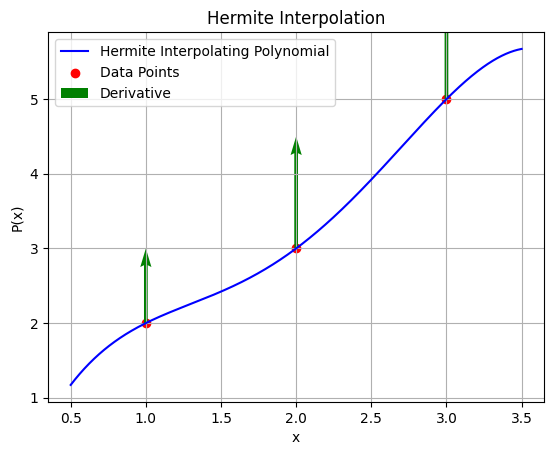

In [238]:
plot_hermite(x, y, dy)